In [10]:
import pandas as pd
df = pd.read_csv("telco.csv.zip")
print(df.shape)
print(df.columns.tolist())
df.head()

(7043, 50)
['Customer ID', 'Gender', 'Age', 'Under 30', 'Senior Citizen', 'Married', 'Dependents', 'Number of Dependents', 'Country', 'State', 'City', 'Zip Code', 'Latitude', 'Longitude', 'Population', 'Quarter', 'Referred a Friend', 'Number of Referrals', 'Tenure in Months', 'Offer', 'Phone Service', 'Avg Monthly Long Distance Charges', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Avg Monthly GB Download', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue', 'Satisfaction Score', 'Customer Status', 'Churn Label', 'Churn Score', 'CLTV', 'Churn Category', 'Churn Reason']


,Customer ID,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,Country,State,...,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Customer Status,Churn Label,Churn Score,CLTV,Churn Category,Churn Reason
0,8779-QRDMV,Male,78,No,Yes,No,No,0,United States,California,...,20,0.00,59.65,3,Churned,Yes,91,5433,Competitor,Competitor offered more data
1,7495-OOKFY,Female,74,No,Yes,Yes,Yes,1,United States,California,...,0,390.80,1024.10,3,Churned,Yes,69,5302,Competitor,Competitor made better offer
2,1658-BYGOY,Male,71,No,Yes,No,Yes,3,United States,California,...,0,203.94,1910.88,2,Churned,Yes,81,3179,Competitor,Competitor made better offer
3,4598-XLKNJ,Female,78,No,Yes,Yes,Yes,1,United States,California,...,0,494.00,2995.07,2,Churned,Yes,88,5337,Dissatisfaction,Limited range of services
4,4846-WHAFZ,Female,80,No,Yes,Yes,Yes,1,United States,California,...,0,234.21,3102.36,2,Churned,Yes,67,2793,Price,Extra data charges


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
df = df.dropna(subset=["Total Charges"])
df["Churn"] = df["Churn Label"].map({"Yes": 1, "No": 0})

print("Customers:", len(df))
print("Overall churn rate:", round(df["Churn"].mean() * 100, 1), "%")

Customers: 7043
Overall churn rate: 26.5 %


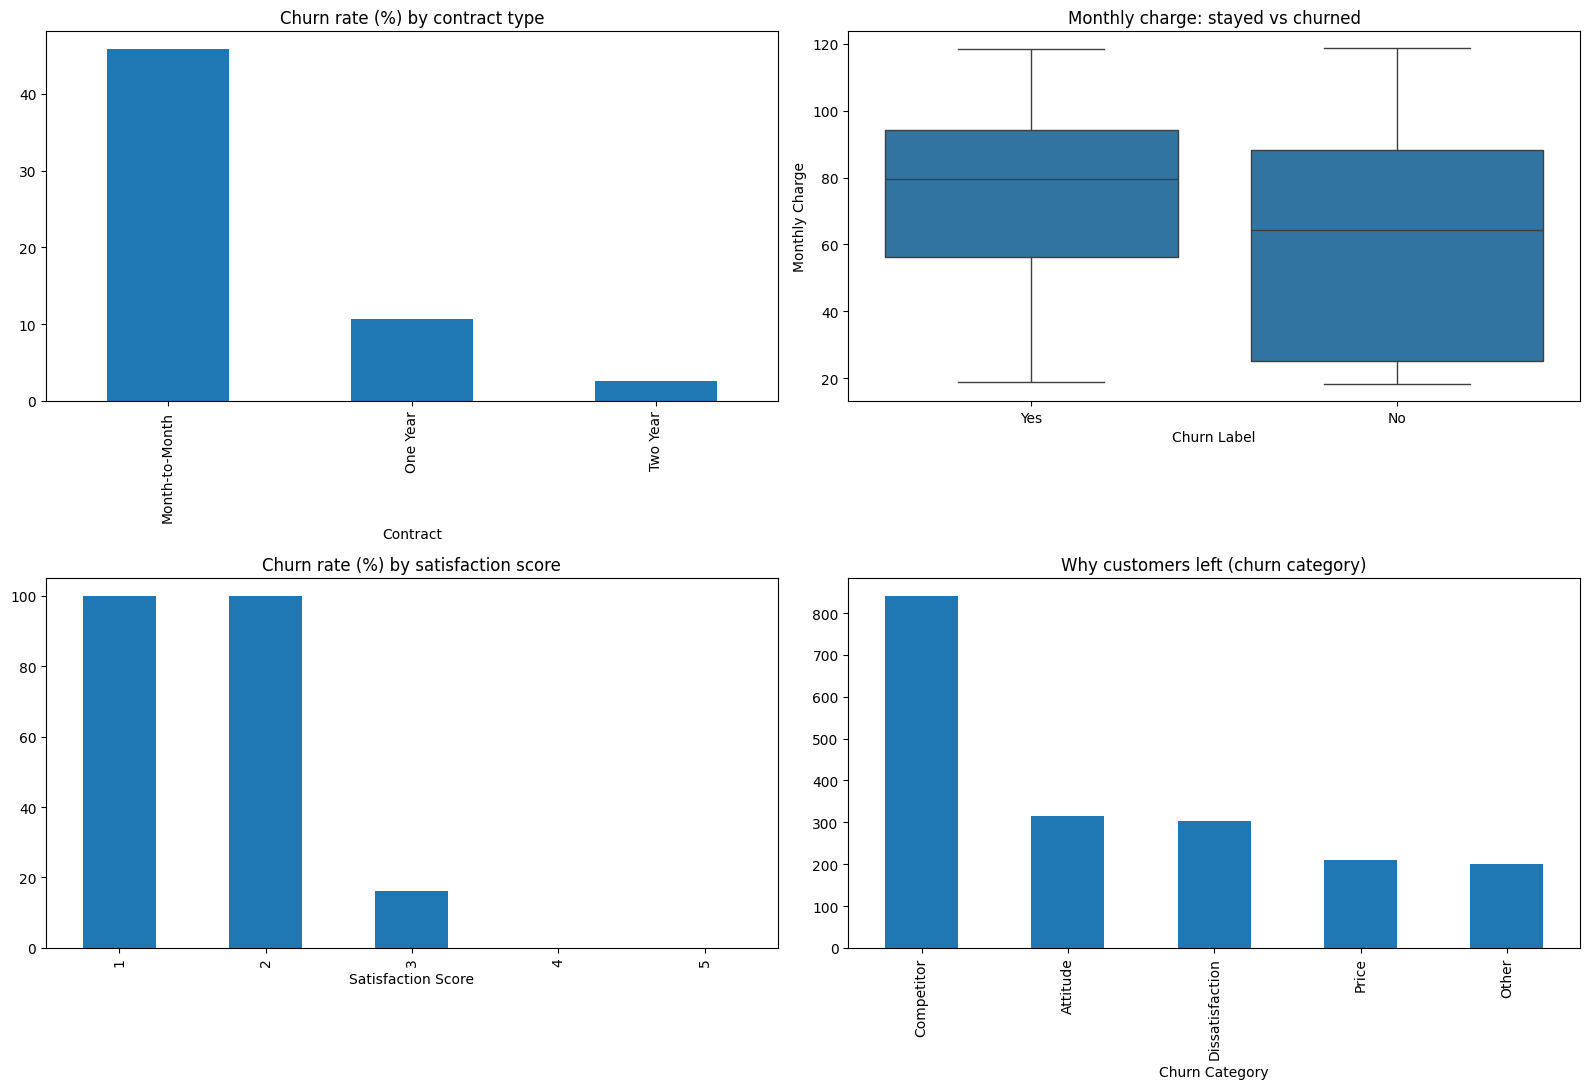

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

df.groupby("Contract")["Churn"].mean().mul(100).plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Churn rate (%) by contract type")

sns.boxplot(x="Churn Label", y="Monthly Charge", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Monthly charge: stayed vs churned")

df.groupby("Satisfaction Score")["Churn"].mean().mul(100).plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Churn rate (%) by satisfaction score")

df[df["Churn"] == 1]["Churn Category"].value_counts().plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Why customers left (churn category)")

plt.tight_layout()
plt.show()

In [13]:
print("Customers:", len(df))
print("Overall churn rate:", round(df["Churn"].mean() * 100, 1), "%")


Customers: 7043
Overall churn rate: 26.5 %


# Customer Churn Analysis (Telco)
**Problem:** A telecom company is losing customers. This analysis identifies which customers churn and why, so the business can target retention actions.
**Data:** 7,043 customers, 50 columns (contract, charges, satisfaction, churn reason).
**Tools:** Python, pandas, matplotlib, seaborn.

In [14]:
import pandas as pd
df = pd.read_csv("telco.csv.zip")
print(df.shape)

(7043, 50)


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
df = df.dropna(subset=["Total Charges"])
df["Churn"] = df["Churn Label"].map({"Yes": 1, "No": 0})

print("Customers:", len(df))
print("Overall churn rate:", round(df["Churn"].mean() * 100, 1), "%")

Customers: 7043
Overall churn rate: 26.5 %


In [16]:
print("Churn rate (%) by contract:")
print(df.groupby("Contract")["Churn"].mean().mul(100).round(1))
print("\nMedian monthly charge by churn status:")
print(df.groupby("Churn Label")["Monthly Charge"].median())
print("\nChurn rate (%) by satisfaction score:")
print(df.groupby("Satisfaction Score")["Churn"].mean().mul(100).round(1))
print("\nChurn categories:")
print(df[df["Churn"] == 1]["Churn Category"].value_counts())

Churn rate (%) by contract:
Contract
Month-to-Month    45.8
One Year          10.7
Two Year           2.5
Name: Churn, dtype: float64

Median monthly charge by churn status:
Churn Label
No     64.425
Yes    79.650
Name: Monthly Charge, dtype: float64

Churn rate (%) by satisfaction score:
Satisfaction Score
1    100.0
2    100.0
3     16.1
4      0.0
5      0.0
Name: Churn, dtype: float64

Churn categories:
Churn Category
Competitor         841
Attitude           314
Dissatisfaction    303
Price              211
Other              200
Name: count, dtype: int64


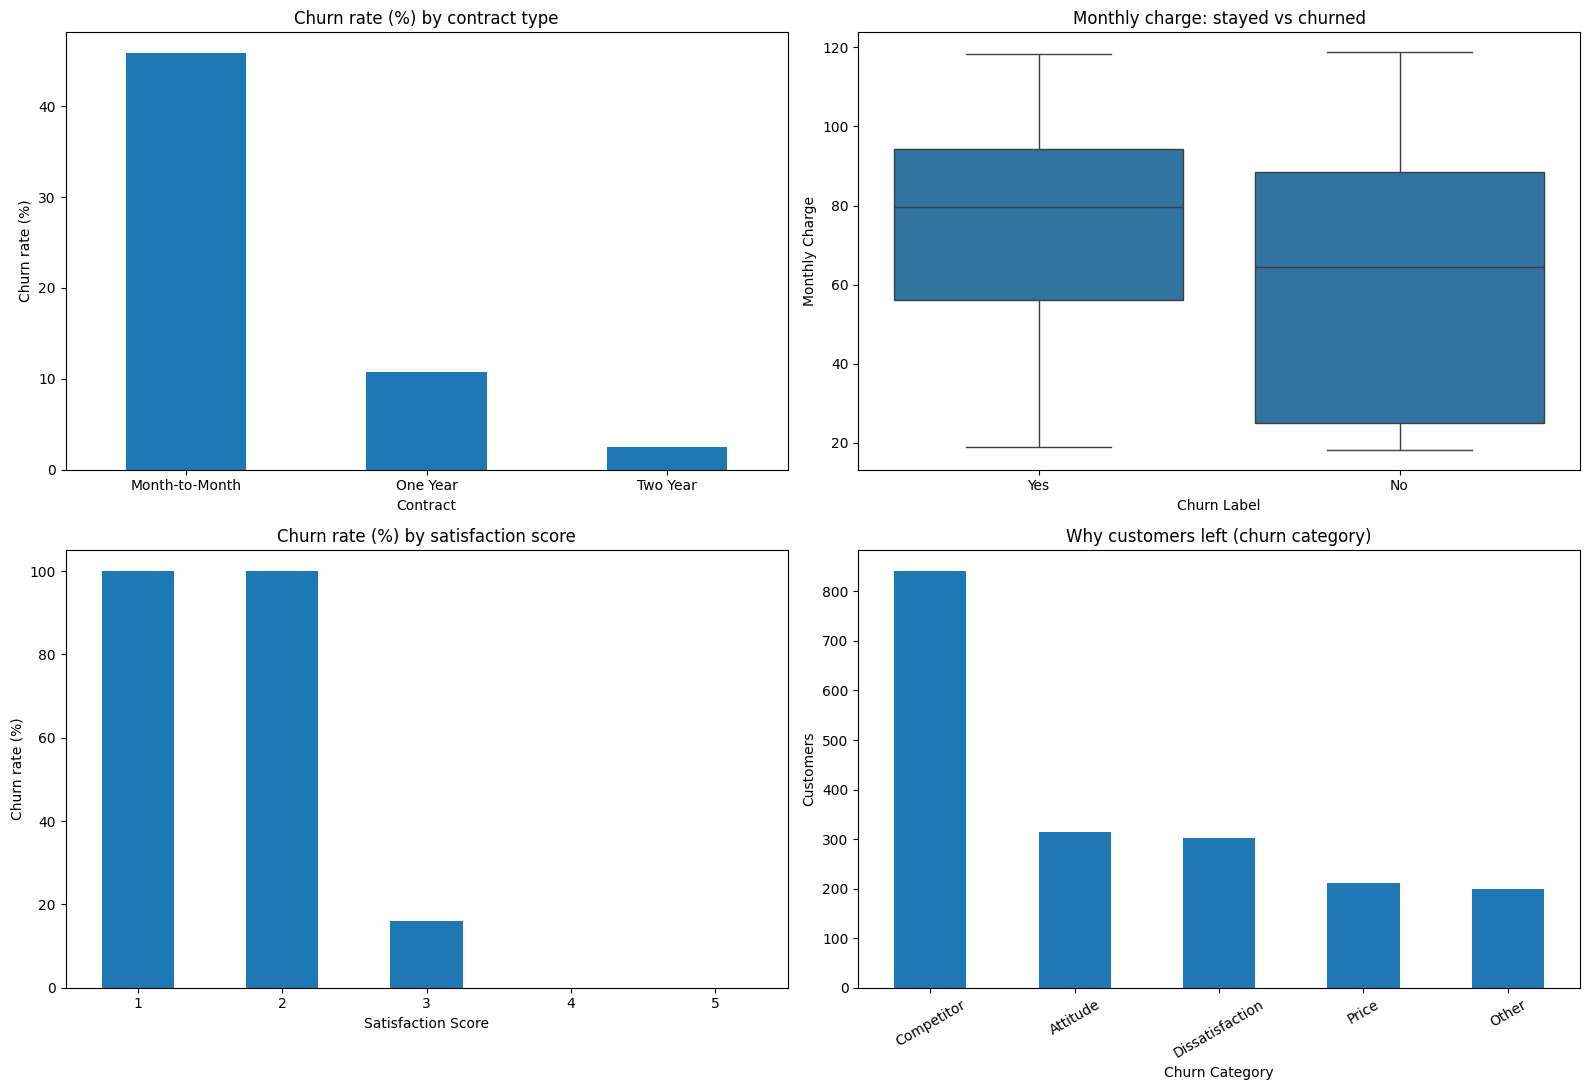

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

df.groupby("Contract")["Churn"].mean().mul(100).plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Churn rate (%) by contract type")
axes[0, 0].set_ylabel("Churn rate (%)")
axes[0, 0].tick_params(axis="x", rotation=0)

sns.boxplot(x="Churn Label", y="Monthly Charge", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Monthly charge: stayed vs churned")

df.groupby("Satisfaction Score")["Churn"].mean().mul(100).plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Churn rate (%) by satisfaction score")
axes[1, 0].set_ylabel("Churn rate (%)")
axes[1, 0].tick_params(axis="x", rotation=0)

df[df["Churn"] == 1]["Churn Category"].value_counts().plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Why customers left (churn category)")
axes[1, 1].set_ylabel("Customers")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Key insights
1. **Contract type:** Month-to-month customers churn at 45.8%, versus 10.7% on one-year and 2.5% on two-year contracts.
2. **Price:** Churned customers paid a higher median monthly charge (79.65) than those who stayed (64.43).
3. **Satisfaction:** Every customer scoring 1 or 2 churned (100%), versus 16.1% at score 3 and 0% at scores 4 and 5. A pattern this extreme suggests the score may have been recorded after the customer decided to leave, so it is a strong association but not proof of cause.
4. **Reasons:** Of 1,869 churned customers, Competitor was the top category (841), followed by Attitude (314), Dissatisfaction (303), Price (211) and Other (200).

## Recommendations
1. Offer incentives to move month-to-month customers onto longer contracts.
2. Trigger outreach when a customer gives a satisfaction score of 1 or 2.
3. Review pricing and offers for high-spending customers, since competitor offers are the top churn reason.